# Customer Segmentation for a retail business

## 1. Data Collection

### 1.1 Data Acquisition

This notebook uses the **Online Retail** transaction dataset. Each row represents an item on an invoice. The main identifiers are `InvoiceNo` for a purchase, `StockCode` for a product, and `CustomerID` for a customer. `Quantity`, `UnitPrice`, `InvoiceDate`, and `Country` provide the behavioral, temporal, and geographic information used later in the analysis.

The analysis starts by loading the raw file and displaying its first rows so the schema and values can be inspected before any cleaning decisions are made.

In [71]:
import pandas as pd
import numpy as np

In [72]:
df = pd.read_csv("Online Retail.csv", encoding="latin-1")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/2010 08:26,3.39,17850.0,United Kingdom


## 2. Data Preprocessing

### 2.1 Data Cleaning

Data cleaning is necessary because clustering is sensitive to missing, duplicated, or invalid numerical values. The cleaning decisions below are documented explicitly so that the customer segments can be reproduced and interpreted consistently.

#### 2.1.1 Handling Missing Values

Missing values are checked by column and then counted across the complete dataframe. Rows with missing customer or transaction information are removed because they cannot contribute reliably to customer-level RFM features. The shape and schema outputs before and after this step provide evidence of how many records remain.

In [73]:
# find shape of df
df.shape

(541909, 8)

In [74]:
# important variables

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.8 MB


In [75]:
# detect if there are columns with missing values
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [76]:
# identify all the missing values in the df
df.isna().sum().sum()

np.int64(136534)

In [77]:
# remove all columns with missing values
df = df.dropna()
df.shape

(406829, 8)

In [78]:
df.info()

# data is clean from missing values

<class 'pandas.DataFrame'>
Index: 406829 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    406829 non-null  str    
 1   StockCode    406829 non-null  str    
 2   Description  406829 non-null  str    
 3   Quantity     406829 non-null  int64  
 4   InvoiceDate  406829 non-null  str    
 5   UnitPrice    406829 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      406829 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 54.2 MB


#### 2.1.2 Handling Abnormal Values

The descriptive statistics identify abnormal transaction values. Non-positive quantities represent returns or invalid transactions for this positive-purchase analysis, while non-positive unit prices cannot produce meaningful revenue. These records are excluded before calculating spending and customer behavior.

In [79]:
df.describe()

# quantity and unit price show a min of 0 to negatives, which could be promotional items, samples, manual adjustments, or data entry errors

,Quantity,UnitPrice,CustomerID
count,406829.000000,406829.000000,406829.000000
mean,12.061303,3.460471,15287.690570
std,248.693370,69.315162,1713.600303
min,-80995.000000,0.000000,12346.000000
25%,2.000000,1.250000,13953.000000
50%,5.000000,1.950000,15152.000000
75%,12.000000,3.750000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [80]:
(df["Quantity"] <= 0).sum()

# items either returned or invalid data

np.int64(8905)

In [81]:
df = df[df["Quantity"] > 0]

df.shape

# only remain with items that are bought

(397924, 8)

In [82]:
(df["UnitPrice"] <= 0).sum()

np.int64(40)

In [83]:
df = df[df["UnitPrice"] > 0]

df.shape

# removed some columns whose unitprice was 0 or less

(397884, 8)

#### 2.1.3 Removing Duplicates

Duplicate invoice-product combinations are aggregated into one record per invoice and product. Quantities are summed because repeated rows may represent the same purchase split across records; the first product description, date, customer, and country values are retained because they identify the same transaction context. This prevents repeated line items from disproportionately affecting customer frequency or spending.

In [84]:
# Check how many rows share the exact same InvoiceNo and StockCode combination
(df.duplicated(subset=["InvoiceNo", "StockCode"], keep=False)).sum()

np.int64(19153)

In [85]:
df = (df.groupby(["InvoiceNo", "StockCode"], as_index=False).agg({
    "Quantity": "sum",
    "UnitPrice": "first",
    "Description": "first",
    "InvoiceDate": "first",
    "CustomerID": "first",
    "Country": "first",
}))

In [86]:
df.describe()

# out of 541909 columns we remaining w 387841

,Quantity,UnitPrice,CustomerID
count,387841.000000,387841.000000,387841.000000
mean,13.324563,3.121278,15282.103251
std,181.672806,21.655710,1713.852379
min,1.000000,0.001000,12346.000000
25%,2.000000,1.250000,13941.000000
50%,6.000000,1.950000,15145.000000
75%,12.000000,3.750000,16790.000000
max,80995.000000,8142.750000,18287.000000


## 3. Exploratory Data Analysis

EDA summarizes the cleaned transactions before modeling. `TotalAmount` converts item quantity and unit price into revenue, while the following views examine products, customers, countries, invoice values, and monthly sales. These summaries help identify skew, concentration, seasonality, and possible business segments that RFM clustering should capture.

In [52]:
# extracting total amount
df["TotalAmount"] = df["Quantity"]*df["UnitPrice"]
df.head()

,InvoiceNo,StockCode,Quantity,UnitPrice,Description,InvoiceDate,CustomerID,Country,TotalAmount
0,536365,21730,6,4.25,GLASS STAR FROSTED T-LIGHT HOLDER,01/12/2010 08:26,17850.0,United Kingdom,25.50
1,536365,22752,2,7.65,SET 7 BABUSHKA NESTING BOXES,01/12/2010 08:26,17850.0,United Kingdom,15.30
2,536365,71053,6,3.39,WHITE METAL LANTERN,01/12/2010 08:26,17850.0,United Kingdom,20.34
3,536365,84029E,6,3.39,RED WOOLLY HOTTIE WHITE HEART.,01/12/2010 08:26,17850.0,United Kingdom,20.34
4,536365,84029G,6,3.39,KNITTED UNION FLAG HOT WATER BOTTLE,01/12/2010 08:26,17850.0,United Kingdom,20.34


In [53]:
(df["TotalAmount"] < 1).sum()

# many sales are still under 1 pound

np.int64(11111)

In [54]:
# checking the different types of products that the store sells

df["StockCode"].value_counts()

# the shop sells 3665 different items

StockCode
85123A    1978
22423     1703
85099B    1600
47566     1379
84879     1375
          ... 
90214T       1
90214U       1
90214W       1
90214Z       1
23843        1
Name: count, Length: 3665, dtype: int64

In [55]:
df["Description"].value_counts()

Description
WHITE HANGING HEART T-LIGHT HOLDER    1971
REGENCY CAKESTAND 3 TIER              1703
JUMBO BAG RED RETROSPOT               1600
PARTY BUNTING                         1379
ASSORTED COLOUR BIRD ORNAMENT         1375
                                      ... 
LETTER "T" BLING KEY RING                1
LETTER "U" BLING KEY RING                1
LETTER "W" BLING KEY RING                1
LETTER "Z" BLING KEY RING                1
PAPER CRAFT , LITTLE BIRDIE              1
Name: count, Length: 3877, dtype: int64

In [56]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Quantity', 'UnitPrice', 'Description',
       'InvoiceDate', 'CustomerID', 'Country', 'TotalAmount'],
      dtype='str')

In [57]:
# purchases per country
df["Country"].value_counts()

Country
United Kingdom          344435
Germany                   9013
France                    8306
EIRE                      7224
Spain                     2463
Netherlands               2359
Belgium                   2031
Switzerland               1841
Portugal                  1438
Australia                 1180
Norway                    1069
Italy                      758
Channel Islands            747
Finland                    681
Cyprus                     599
Sweden                     450
Austria                    398
Denmark                    379
Poland                     330
Japan                      321
Israel                     245
Unspecified                239
Singapore                  218
Iceland                    182
USA                        179
Canada                     151
Greece                     145
Malta                      112
United Arab Emirates        68
European Community          60
RSA                         57
Lebanon                     45


In [58]:
# different customers in the store
df["CustomerID"].value_counts()

# so thats 4338 different customers, some taking several items over the span of the year while others just one

CustomerID
17841.0    7477
14911.0    5670
14096.0    5080
12748.0    4284
14606.0    2660
           ... 
18084.0       1
18184.0       1
13017.0       1
18174.0       1
15195.0       1
Name: count, Length: 4338, dtype: int64

In [59]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 387841 entries, 0 to 387840
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    387841 non-null  str    
 1   StockCode    387841 non-null  str    
 2   Quantity     387841 non-null  int64  
 3   UnitPrice    387841 non-null  float64
 4   Description  387841 non-null  str    
 5   InvoiceDate  387841 non-null  str    
 6   CustomerID   387841 non-null  float64
 7   Country      387841 non-null  str    
 8   TotalAmount  387841 non-null  float64
dtypes: float64(3), int64(1), str(5)
memory usage: 51.5 MB


In [60]:
# data formatting
# converting date from obj/str to datetime

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], dayfirst=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 387841 entries, 0 to 387840
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    387841 non-null  str           
 1   StockCode    387841 non-null  str           
 2   Quantity     387841 non-null  int64         
 3   UnitPrice    387841 non-null  float64       
 4   Description  387841 non-null  str           
 5   InvoiceDate  387841 non-null  datetime64[us]
 6   CustomerID   387841 non-null  float64       
 7   Country      387841 non-null  str           
 8   TotalAmount  387841 non-null  float64       
dtypes: datetime64[us](1), float64(3), int64(1), str(4)
memory usage: 45.6 MB


In [61]:
# 3. Group by Invoice and metadata to get one row per visit
invoice_df = (
    df.groupby(
        ["InvoiceNo", "CustomerID", "InvoiceDate", "Country"], as_index=False
    )
    .agg(
        # Total money spent on this visit
        TotalSpending=("TotalAmount", "sum"),
        # Total units of items bought in this visit
        TotalItems=("Quantity", "sum"),
        UniqueProducts=(
            "StockCode",
            "nunique",
        ),  # Number of distinct product types
    )
    .sort_values(by="InvoiceDate")
)

invoice_df.head()

,InvoiceNo,CustomerID,InvoiceDate,Country,TotalSpending,TotalItems,UniqueProducts
0,536365,17850.0,2010-12-01 08:26:00,United Kingdom,139.12,40,7
1,536366,17850.0,2010-12-01 08:28:00,United Kingdom,22.20,12,2
2,536367,13047.0,2010-12-01 08:34:00,United Kingdom,278.73,83,12
3,536368,13047.0,2010-12-01 08:34:00,United Kingdom,70.05,15,4
4,536369,13047.0,2010-12-01 08:35:00,United Kingdom,17.85,3,1


In [62]:
# visualise purchases per country
import seaborn as sns
import matplotlib.pyplot as plt

group1 = invoice_df.groupby(
    "Country")["TotalSpending"].mean().sort_values(ascending=False)
group1

Country
Netherlands             3036.663191
Singapore               2817.500000
Australia               2430.198421
Japan                   1870.818500
Lebanon                 1693.880000
Israel                  1444.338000
Brazil                  1143.600000
Switzerland             1106.744118
Sweden                  1066.064722
Denmark                 1052.796667
EIRE                    1017.410345
Norway                  1012.628889
RSA                     1002.310000
Greece                   952.104000
Cyprus                   849.398750
Channel Islands          786.555385
USA                      716.078000
Spain                    684.190111
United Arab Emirates     634.093333
Iceland                  615.714286
Canada                   611.063333
Austria                  599.922353
Portugal                 586.664737
Finland                  551.426341
Malta                    545.118000
France                   535.959103
Germany                  498.835098
Italy               

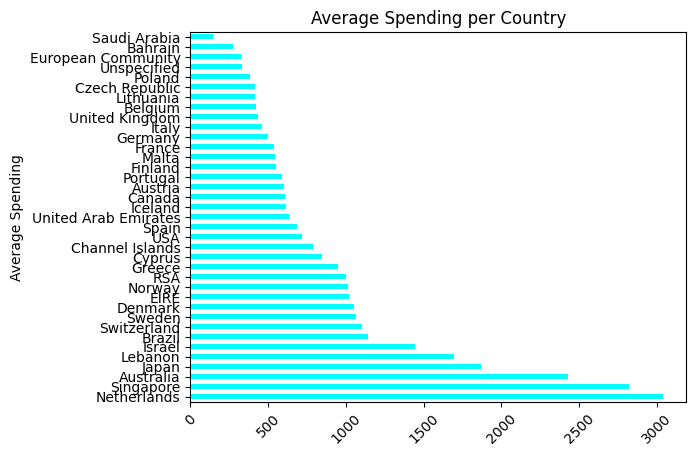

In [63]:
group1.plot(kind="barh", color="cyan")
plt.title("Average Spending per Country")
plt.ylabel("Average Spending")
plt.xticks(rotation=45)
plt.show()

In [64]:
# no of customers per country
group2 = invoice_df.groupby(
    "Country")["CustomerID"].count().sort_values(ascending=False)
group2

Country
United Kingdom          16673
Germany                   457
France                    390
EIRE                      261
Belgium                    98
Netherlands                94
Spain                      90
Portugal                   57
Australia                  57
Switzerland                51
Finland                    41
Italy                      38
Sweden                     36
Norway                     36
Channel Islands            26
Japan                      20
Poland                     19
Denmark                    18
Austria                    17
Cyprus                     16
Unspecified                 8
Iceland                     7
Singapore                   7
Canada                      6
Greece                      5
Malta                       5
Israel                      5
USA                         5
Lithuania                   4
European Community          4
United Arab Emirates        3
Czech Republic              2
Bahrain                     2
Br

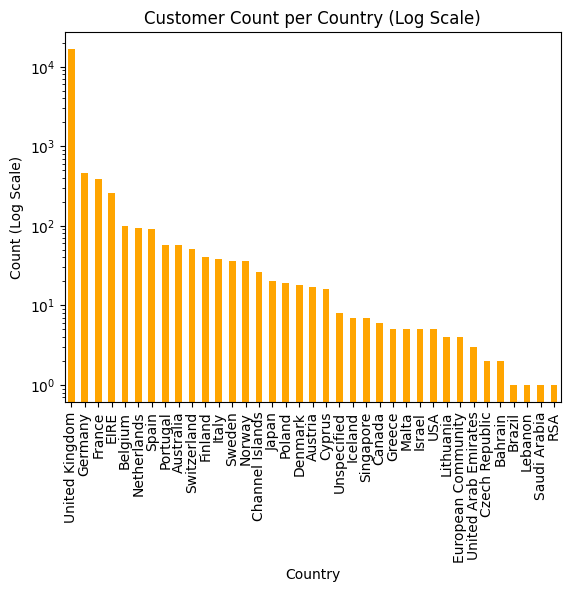

In [65]:
group2.plot(kind="bar", logy=True, color="orange")
plt.title("Customer Count per Country (Log Scale)")
plt.ylabel("Count (Log Scale)")
plt.xticks(rotation=90)
plt.show()

Temporal Patterns (Time-Based EDA)
What to look for: When do customers buy? You can extract the hour, day of the week, and month from InvoiceDate.

Key Insight: Retail data typically shows massive spikes leading up to the holidays (e.g., November/December) and clear daily shopping hours (e.g., mid-day peaks). This helps explain seasonality in customer behavior.

In [66]:
invoice_df.columns

Index(['InvoiceNo', 'CustomerID', 'InvoiceDate', 'Country', 'TotalSpending',
       'TotalItems', 'UniqueProducts'],
      dtype='str')

In [67]:
# monthly distribution of sales
# Extract year-month (e.g., '2010-12', '2011-01')
invoice_df["YearMonth"] = invoice_df["InvoiceDate"].dt.to_period("M")

# Group by month and calculate total spending
monthly_sales = invoice_df.groupby(
    "YearMonth")["TotalSpending"].sum().reset_index()

monthly_sales

,YearMonth,TotalSpending
0,2010-12,572751.400
1,2011-01,569445.040
2,2011-02,447256.810
3,2011-03,595785.640
4,2011-04,465816.591
5,2011-05,678599.760
6,2011-06,661309.290
7,2011-07,600108.931
8,2011-08,645342.460
9,2011-09,952917.131


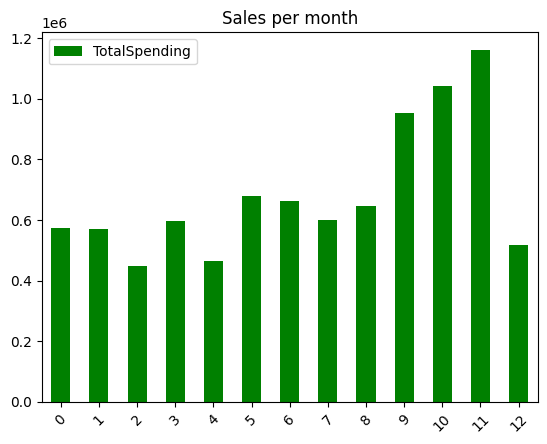

In [68]:
monthly_sales.plot(kind="bar", color="green")
plt.title("Sales per month")
# plt.ylabel("Count (Log Scale)")
plt.xticks(rotation=45)
plt.show()

## 4. Model Training and Evaluation

,k,inertia,silhouette,calinski_harabasz
0,2,6481.336040,0.432935,4370.340513
1,3,4867.549248,0.336606,3627.619187
2,4,3938.653065,0.337525,3328.825561
3,5,3295.882790,0.316117,3194.073267
4,6,2854.779004,0.313399,3083.236417
5,7,2548.748524,0.310020,2963.882321
6,8,2343.045893,0.291363,2817.190515
7,9,2155.310735,0.281414,2726.246445
8,10,1999.621704,0.278810,2648.873855


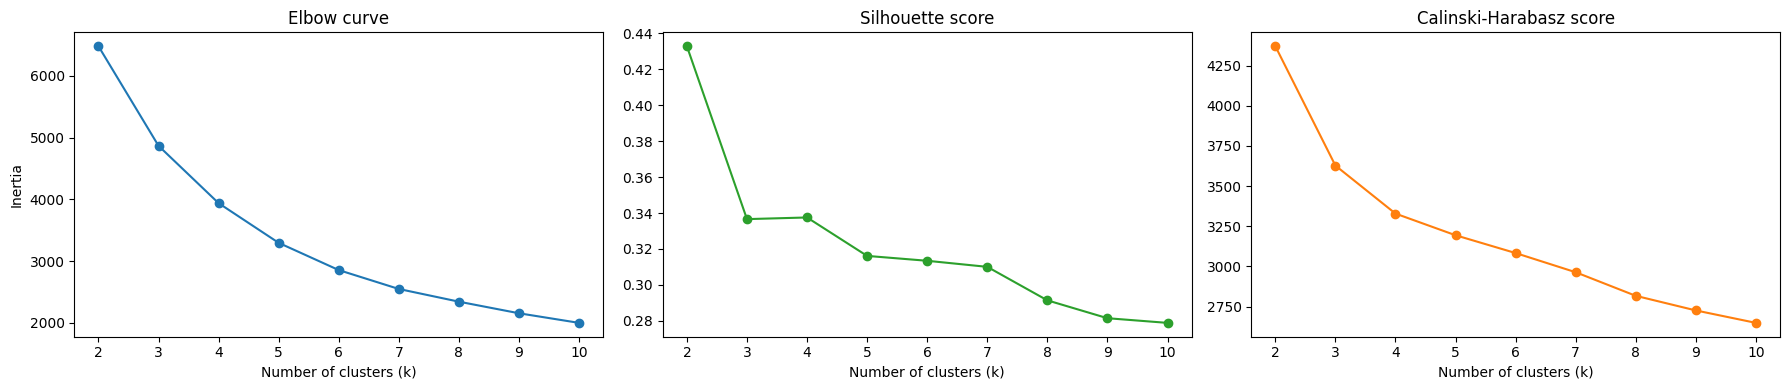

Recency                Frequency               Monetary           \
          count    mean median     count   mean median    count     mean   
Cluster                                                                    
0           769   17.03    9.0       769  13.35   10.0      769  7907.61   
1          1872  167.36  158.0      1872   1.35    1.0     1872   362.61   
2          1697   44.21   30.0      1697   3.38    3.0     1697  1266.95   

                  
          median  
Cluster           
0        3707.12  
1         298.06  
2         979.26

,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346.0,326,1,77183.60,2,Customer Segment 3
1,12347.0,2,7,4310.00,0,Customer Segment 1
2,12348.0,75,4,1859.64,2,Customer Segment 3
3,12349.0,19,1,1757.55,2,Customer Segment 3
4,12350.0,310,1,334.40,1,Customer Segment 2


In [69]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from sklearn.preprocessing import StandardScaler

# Build one customer-level RFM record from the cleaned transaction table.
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = (
    df.groupby("CustomerID")
    .agg(
        Recency=("InvoiceDate", lambda dates: (
            snapshot_date - dates.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("TotalAmount", "sum"),
    )
    .reset_index()
)

rfm_features = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

# Compare candidate cluster counts with inertia and two separation metrics.
k_values = range(2, 11)
inertias = []
silhouette_scores = []
calinski_scores = []
for k in k_values:
    candidate = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = candidate.fit_predict(rfm_scaled)
    inertias.append(candidate.inertia_)
    silhouette_scores.append(silhouette_score(rfm_scaled, labels))
    calinski_scores.append(calinski_harabasz_score(rfm_scaled, labels))

metrics_by_k = pd.DataFrame({
    "k": list(k_values),
    "inertia": inertias,
    "silhouette": silhouette_scores,
    "calinski_harabasz": calinski_scores,
})
display(metrics_by_k)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(metrics_by_k["k"], metrics_by_k["inertia"], marker="o")
axes[0].set_title("Elbow curve")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[1].plot(metrics_by_k["k"], metrics_by_k["silhouette"],
             marker="o", color="tab:green")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (k)")
axes[2].plot(metrics_by_k["k"], metrics_by_k["calinski_harabasz"],
             marker="o", color="tab:orange")
axes[2].set_title("Calinski-Harabasz score")
axes[2].set_xlabel("Number of clusters (k)")
plt.tight_layout()
plt.show()

# Three segments provide an interpretable baseline for customer tiering.
final_k = 3
final_model = KMeans(n_clusters=final_k, random_state=42, n_init=10)
rfm["Cluster"] = final_model.fit_predict(rfm_scaled)
cluster_profile = (
    rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]]
    .agg(["count", "mean", "median"])
    .round(2)
)
display(cluster_profile)

rfm["Segment"] = rfm["Cluster"].map({
    cluster: f"Customer Segment {cluster + 1}" for cluster in sorted(rfm["Cluster"].unique())
})
display(rfm.head())

### How to Read the Clustering Output

The metrics table reports one row per candidate `k`. Inertia should decrease as `k` increases, so the elbow is the point where additional clusters produce smaller improvements. A higher silhouette score indicates better separation and cohesion, while a higher Calinski-Harabasz score indicates compact, distinct clusters.

The profile table is expressed in the original RFM units rather than the scaled values. Use Recency, Frequency, and Monetary together when naming segments: a single metric alone is not enough to describe customer value or engagement. The `rfm` table retains one row per customer and the assigned cluster, making it suitable for later campaign targeting.